# Task 2.2: How often does it phase flip?

**Method.** Same idea: the slowest nonzero "even" eigenvalue is the phase flip rate. Cross-checked against the parity decay of the even cat.

In [1]:
import sys, json, glob
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
S2 = ROOT / 'results/s2'
load = lambda pat: [json.loads(Path(f).read_text()) for f in sorted(glob.glob(str(S2 / pat)))]
show = lambda name, w=750: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))
sys.path.insert(0, str(ROOT))
from research.s2.common import KAPPA_A
nominal = lambda d: d['eps_z_over_g2'] == 0 and d['n_th'] == 0 and d['kappa_a'] == KAPPA_A and abs(d['kappa_b'] - 16.3363) < 1e-3

def largest(rows):
    best = {}
    for d in rows:
        k = round(d['alpha'], 2)
        if k not in best or d['na'] * d['nb'] > best[k]['na'] * best[k]['nb']:
            best[k] = d
    return best

In [2]:
best = largest(d for d in load('gx_two_*.json') if nominal(d) and 'gamma_z_eig' in d)
pd.DataFrame([{'alpha': a, 'photons': round(a * a, 2), 'phase flip rate (1/µs)': round(d['gamma_z_eig'], 4)}
              for a, d in sorted(best.items()) if a in (1.0, 1.4, 1.8, 2.1, 2.4)])

,alpha,photons,phase flip rate (1/µs)
0,1.0,1.00,0.1206
1,1.4,1.96,0.2284
2,1.8,3.24,0.3778
3,2.1,4.41,0.5146
4,2.4,5.76,0.6723


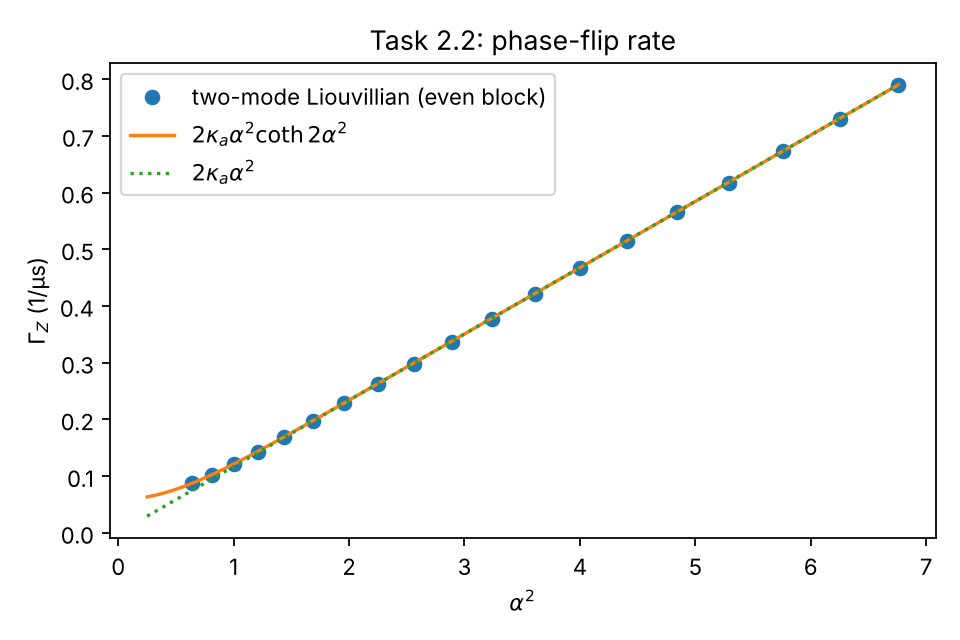

In [3]:
show('gamma_z', 600)

**Result.** Phase flips grow in **direct proportion to the photon number**: slope 0.991 × the textbook 2κ_a. The eigenvalue and the parity fit agree to 5 digits (0.51455 vs 0.51456 per µs at α = 2.1).